# 4. Forecasting daily entries for November 2025

Forecasts daily entry taps for one representative station per cluster for 1 to 30 November 2025. The data end on 13 September 2025, so there is a gap of roughly eight weeks between the last usable observation and the first forecast day, and October is never observed.

Two forecasts are produced:

| | Window | Horizon (days) | Model |
|---|---|---|---|
| Near | 14 to 27 September 2025 | 10 to 23 | calendar and lag features |
| Far | 1 to 30 November 2025 | 58 to 87 | calendar features only |

The near forecast is included to measure what lag features are worth when recent history is available.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import tfl

In [2]:
COUNTS_CSV = "../data/processed/TfL_Data_Processed.csv"
CLUSTERS_CSV = "../outputs/station_clustering_results.csv"
OUT_CSV = "../outputs/november_forecasts.csv"

ORIGIN = pd.Timestamp("2025-09-04")          # last usable day before the strike

NEAR_TARGET = pd.date_range("2025-09-14", "2025-09-27", freq="D")
FAR_TARGET = pd.date_range("2025-11-01", "2025-11-30", freq="D")

TARGET = FAR_TARGET
GAP_DAYS = (TARGET.min() - ORIGIN).days
NEAR_H = ((NEAR_TARGET.min() - ORIGIN).days, (NEAR_TARGET.max() - ORIGIN).days)
FAR_H = ((FAR_TARGET.min() - ORIGIN).days, (FAR_TARGET.max() - ORIGIN).days)

MIN_TRAIN_DAYS = 240

TAIL_DAYS = 28
MIN_COVERAGE = 0.95

print(f"Origin {ORIGIN:%Y-%m-%d}")
print(f"  near: {NEAR_TARGET.min():%Y-%m-%d} to {NEAR_TARGET.max():%Y-%m-%d}"
      f"   horizons {NEAR_H[0]}-{NEAR_H[1]} days")
print(f"  far : {FAR_TARGET.min():%Y-%m-%d} to {FAR_TARGET.max():%Y-%m-%d}"
      f"   horizons {FAR_H[0]}-{FAR_H[1]} days")

Origin 2025-09-04
  near: 2025-09-14 to 2025-09-27   horizons 10-23 days
  far : 2025-11-01 to 2025-11-30   horizons 58-87 days


## 4.1 Data preparation

Each station is placed on a complete daily index, so that missing dates remain as missing values instead of silently shortening the series. The strike week is masked rather than deleted. Days outside 0.25 to 1.75 times the station's median for that weekday are treated as disrupted and masked. Bank holidays are exempt from the filter and are modelled with their own indicator.

In [3]:
counts = tfl.load_counts(COUNTS_CSV)

In [4]:
# Counts around the strike at Underground, DLR, Overground and Elizabeth line stations.
window = counts[counts["TravelDate"].between("2025-09-03", "2025-09-13")]
check = window.pivot_table(index="Station", columns="TravelDate",
                           values="EntryTapCount")
check.columns = [c.strftime("%d %b") for c in check.columns]

rows = ["Ruislip Manor", "W Silvertown", "Pontoon Dock DLR",
        "Bethnal Green NR", "Abbey Wood"]
print("Underground / DLR / Overground / Elizabeth line, 3-13 September 2025\n")
print(check.loc[[r for r in rows if r in check.index]].round(0).to_string())

Underground / DLR / Overground / Elizabeth line, 3-13 September 2025

                   03 Sep   04 Sep   05 Sep   06 Sep  07 Sep   08 Sep   09 Sep   10 Sep   11 Sep   12 Sep   13 Sep
Station                                                                                                           
Ruislip Manor      2219.0   2562.0   2382.0   1870.0   572.0    350.0      4.0    229.0      1.0   1646.0   1716.0
W Silvertown       1824.0   2658.0   2681.0    784.0   507.0   1609.0      1.0   2296.0      1.0   2478.0    710.0
Pontoon Dock DLR   2245.0   3369.0   3178.0    711.0   499.0   1419.0      0.0   2075.0      0.0   2802.0    690.0
Bethnal Green NR   2386.0   2139.0   2789.0   2861.0  1301.0   3373.0   3743.0   3927.0   4051.0   2831.0   2204.0
Abbey Wood        18223.0  19603.0  18312.0  14238.0  9733.0  14940.0  16940.0  16345.0  17125.0  17413.0  14031.0


## 4.2 Representative stations

Candidates must report on every day of the final 28 (excluding the strike week) and have at least 95% date coverage. The station nearest each centroid is then chosen, with the number of disrupted days as a secondary check. The DBSCAN noise flag is not used, because the commuter cluster lies in a sparse region of the feature space and all of its members are flagged.

In [5]:
clusters = pd.read_csv(CLUSTERS_CSV)

last_date = counts["TravelDate"].max()
tail_start = last_date - pd.Timedelta(days=TAIL_DAYS)

in_tail = counts["TravelDate"].between(tail_start, last_date)
in_strike = counts["TravelDate"].between(*tfl.STRIKE)
tail = counts[in_tail & ~in_strike]

days_expected = tail["TravelDate"].nunique()
days_reported = tail.groupby("Station")["TravelDate"].nunique()

clusters["TailDays"] = clusters["Station"].map(days_reported).fillna(0)
eligible = clusters[
    (clusters["TailDays"] == days_expected)
    & (clusters["DateCoverage"] >= MIN_COVERAGE)
]

candidates = (eligible.sort_values("CentroidDist")
                      .groupby("Cluster")
                      .head(3)
                      .sort_values(["Cluster", "CentroidDist"]))

print(f"{len(eligible)} of {len(clusters)} stations eligible\n")
print(candidates[["Cluster", "ClusterName", "Station", "CentroidDist",
                  "SilhouetteScore"]].to_string(index=False))

392 of 434 stations eligible

 Cluster                     ClusterName          Station  CentroidDist  SilhouetteScore
       0             Low volume stations      Wood Street      0.257575         0.344323
       0             Low volume stations Bethnal Green NR      0.421879         0.392038
       0             Low volume stations          Hanwell      0.451764         0.294307
       1 Consistent high-volume stations         Southall      0.247109         0.536220
       1 Consistent high-volume stations          Kilburn      0.364196         0.498011
       1 Consistent high-volume stations   West Hampstead      0.374534         0.520988
       2       Weekday commuter stations        Southwark      0.467924         0.249232
       2       Weekday commuter stations          Aldgate      0.572118         0.293289
       2       Weekday commuter stations  St James's Park      0.635099         0.224298


In [6]:
for name in candidates["Station"]:
    df = tfl.build_series(counts, name)
    print(f"{name:26s} closures {df['IsDisrupted'].sum():3d}   "
          f"coverage {df['Entries'].notna().mean():.3f}")

Wood Street                closures  27   coverage 0.994
Bethnal Green NR           closures  17   coverage 0.997
Hanwell                    closures  28   coverage 0.966
Southall                   closures   3   coverage 0.997
Kilburn                    closures  12   coverage 0.986
West Hampstead             closures   6   coverage 0.990


Southwark                  closures  36   coverage 0.963


Aldgate                    closures  15   coverage 0.990
St James's Park            closures  18   coverage 0.989


In [7]:
# The eligible station nearest each centroid, in a fixed cluster order.
STATIONS = (candidates.groupby("ClusterName").head(1)
                      .set_index("ClusterName")
                      .loc[tfl.CLUSTER_ORDER, "Station"]
                      .tolist())
print(STATIONS)
series = {s: tfl.build_series(counts, s) for s in STATIONS}

for s, df in series.items():
    ok = df["y"].notna()
    print(f"{s:16s} usable {ok.sum():3d}/{len(df)}   "
          f"mean {df.loc[ok, 'y'].mean():8,.0f}   "
          f"last usable {df.loc[ok, 'Date'].max():%Y-%m-%d}")

['Southwark', 'Wood Street', 'Southall']


Southwark        usable 580/622   mean   12,393   last usable 2025-09-13
Wood Street      usable 584/622   mean    2,766   last usable 2025-09-13
Southall         usable 609/622   mean    9,765   last usable 2025-09-13


## 4.3 Calendar features

Six day-of-week indicators (Monday is the reference level), Fourier terms for the annual cycle, and indicators for bank holidays and the Christmas period. Every feature is known exactly for any future date.

In [8]:
# Effect of a linear trend term when the training window is short.
def features_with_trend(df):
    X = tfl.features_for(df)
    X["trend"] = ((df["Date"] - pd.Timestamp("2024-01-01")).dt.days / 365.25).values
    return X


station = STATIONS[1]
df_tr = tfl.build_series(counts, station, extend_to=FAR_TARGET.max())
X_trend = features_with_trend(df_tr)
X_flat = tfl.features_for(df_tr)

is_train = df_tr["Date"].between("2025-01-01", ORIGIN).values & df_tr["y"].notna().values
is_future = df_tr["Date"].isin(FAR_TARGET).values
y_train = df_tr["y"].values[is_train]

with_trend = tfl.fit_predict(X_trend[is_train], y_train, X_trend[is_future], "poisson")
calendar_only = tfl.fit_predict(X_flat[is_train], y_train, X_flat[is_future], "poisson")

recent = df_tr.loc[df_tr["y"].notna() & (df_tr["Date"] >= "2025-06-01"), "y"].mean()

print(f"{station}, trained 2025-01-01 to {ORIGIN:%Y-%m-%d}, predicting November 2025\n")
print(f"  observed level, Jun-Sep 2025       {recent:>9,.0f} per day")
print(f"  with trend term,   1 Nov -> 30 Nov {with_trend[0]:>9,.0f} -> {with_trend[-1]:,.0f}")
print(f"  calendar only,     1 Nov -> 30 Nov {calendar_only[0]:>9,.0f} -> {calendar_only[-1]:,.0f}")
print(f"\n  November total, with trend         {with_trend.sum():>9,.0f}")
print(f"  November total, calendar only      {calendar_only.sum():>9,.0f}")
print(f"  ratio                              {with_trend.sum() / calendar_only.sum():>9.2f}x")

Wood Street, trained 2025-01-01 to 2025-09-04, predicting November 2025

  observed level, Jun-Sep 2025           2,849 per day
  with trend term,   1 Nov -> 30 Nov     4,132 -> 4,149
  calendar only,     1 Nov -> 30 Nov     2,056 -> 1,388

  November total, with trend           170,808
  November total, calendar only         68,817
  ratio                                   2.48x


## 4.4 Models

| Name | Model |
|---|---|
| `naive` | day-of-week means over the last eight weeks |
| `poisson` | Poisson GLM with a log link |
| `lognormal` | ridge regression on log(y), back-transformed with Duan's smearing estimate |
| `xgb` | gradient-boosted trees with a Poisson objective |

## 4.5 Backtesting

Each backtest origin forecasts a 30-day window starting `GAP_DAYS` after the origin, so that the validation horizon matches the November task.

In [9]:
backtests = {s: tfl.rolling_backtest(df, GAP_DAYS, min_train_days=MIN_TRAIN_DAYS)
             for s, df in series.items()}
print(f"{backtests[STATIONS[0]]['origin'].nunique()} origins per station")

10 origins per station


In [10]:
summary = {}
for s, bt in backtests.items():
    t = bt.pivot_table(index="model", values=["mae", "mase", "bias"]).reindex(tfl.MODEL_NAMES)
    t["vsNaive"] = t["mae"] / t.loc["naive", "mae"]
    summary[s] = t

print("MAE relative to seasonal naive\n")
print(pd.DataFrame({s: summary[s]["vsNaive"] for s in STATIONS}).round(3).to_string())
print("\nMASE\n")
print(pd.DataFrame({s: summary[s]["mase"] for s in STATIONS}).round(3).to_string())
print("\nBias, (actual - predicted) / mean actual\n")
print(pd.DataFrame({s: summary[s]["bias"] for s in STATIONS}).round(3).to_string())

MAE relative to seasonal naive

           Southwark  Wood Street  Southall
model                                      
naive          1.000        1.000     1.000
poisson        0.886        0.826     1.062
lognormal      0.978        0.809     1.044
xgb            0.750        0.895     1.122

MASE

           Southwark  Wood Street  Southall
model                                      
naive          1.128        1.316     1.418
poisson        1.000        1.087     1.506
lognormal      1.103        1.065     1.481
xgb            0.846        1.178     1.592

Bias, (actual - predicted) / mean actual

           Southwark  Wood Street  Southall
model                                      
naive         -0.014        0.007     0.008
poisson        0.003        0.057     0.084
lognormal      0.001        0.055     0.083
xgb            0.003        0.072     0.093


In [11]:
# Seasonal analogue of the task: origin September 2024, target November 2024.
o = pd.Timestamp("2024-09-04")
tgt = pd.date_range("2024-11-01", "2024-11-30", freq="D")

rows = []
for s, df in series.items():
    pred = tfl.forecast(df, o, tgt)
    act = df.set_index("Date")["y"].reindex(tgt).values
    for m in tfl.MODEL_NAMES:
        e = act - pred[m].values
        k = ~np.isnan(e)
        rows.append({"station": s, "model": m, "MAE": np.abs(e[k]).mean(),
                     "bias": e[k].mean() / act[k].mean()})

print("Origin 2024-09-04 -> November 2024\n")
print(pd.DataFrame(rows).pivot(index="station", columns="model",
                               values=["MAE", "bias"]).round(3).to_string())

Origin 2024-09-04 -> November 2024

                  MAE                                    bias                      
model       lognormal     naive   poisson       xgb lognormal  naive poisson    xgb
station                                                                            
Southall     2408.576   982.039  2393.190   914.339     0.229  0.013   0.227  0.060
Southwark    5603.253  1651.723  5048.796  1968.314     0.426  0.121   0.384  0.145
Wood Street   868.888   612.878   867.468   708.121     0.279  0.183   0.279  0.212


In [12]:
# The same horizon in two different seasons.
rows = []
windows = [
    ("Mar -> May 2025", pd.Timestamp("2025-03-05"),
     pd.date_range("2025-05-01", "2025-05-30", freq="D")),
    ("Sep -> Nov 2024", pd.Timestamp("2024-09-04"),
     pd.date_range("2024-11-01", "2024-11-30", freq="D")),
]

for label, origin, target in windows:
    for s, df in series.items():
        pred = tfl.forecast(df, origin, target, models=["poisson"])
        act = df.set_index("Date")["y"].reindex(target).values
        e = act - pred["poisson"].values
        k = ~np.isnan(e)
        rows.append({"window": label, "station": s,
                     "MAE": np.abs(e[k]).mean(),
                     "bias": e[k].mean() / act[k].mean()})

seasons = pd.DataFrame(rows)
print("Poisson GLM, horizon held at about 58 days, season varied\n")
print("bias, (actual - predicted) / mean actual\n")
print(seasons.pivot(index="window", columns="station", values="bias").round(3).to_string())
print("\nMAE\n")
print(seasons.pivot(index="window", columns="station", values="MAE").round(0).to_string())

Poisson GLM, horizon held at about 58 days, season varied

bias, (actual - predicted) / mean actual

station          Southall  Southwark  Wood Street
window                                           
Mar -> May 2025     0.090     -0.080        0.052
Sep -> Nov 2024     0.227      0.384        0.279

MAE

station          Southall  Southwark  Wood Street
window                                           
Mar -> May 2025     929.0     1080.0        229.0
Sep -> Nov 2024    2393.0     5049.0        867.0


## 4.6 Diagnostics

In [13]:
# Number of annual harmonics, and sensitivity of the choice to the number of origins.
scores = {}
for k in [1, 2, 3, 4]:
    for n in [6, 10]:
        vals = []
        for s, df in series.items():
            bt = tfl.rolling_backtest(df, GAP_DAYS, n_origins=n,
                                      min_train_days=MIN_TRAIN_DAYS, k=k,
                                      models=["poisson"])
            t = bt.pivot_table(index="model", values="mae")
            vals.append(t.loc["poisson", "mae"] / t.loc["naive", "mae"])
        scores[(k, n)] = np.mean(vals)

table = pd.Series(scores).unstack()
table.index.name = "harmonics"
table.columns.name = "origins"
print("Poisson MAE relative to naive\n")
print(table.round(3).to_string())

Poisson MAE relative to naive

origins       6      10
harmonics              
1          0.804  0.829
2          0.866  0.925
3          0.885  0.971
4          0.869  0.963


In [14]:
# Error by horizon for the calendar-only model.
rows = []
for s, df in series.items():
    first, last = df["Date"].min(), df["Date"].max()
    origins = [last - pd.Timedelta(days=88 + 30 * i) for i in range(8)]
    origins = [o for o in origins if (o - first).days >= MIN_TRAIN_DAYS]

    for o in origins:
        tgt = pd.date_range(o + pd.Timedelta(days=1), periods=88, freq="D")
        pred = tfl.forecast(df, o, tgt, models=["poisson"])
        act = df.set_index("Date")["y"].reindex(tgt).values
        rows.append(pd.DataFrame({"station": s, "h": np.arange(1, 89),
                                  "ae": np.abs(act - pred["poisson"].values)}))

d = pd.concat(rows).dropna()
d["bucket"] = pd.cut(d["h"], [0, 14, 28, 42, 56, 70, 88],
                     labels=["1-14", "15-28", "29-42", "43-56", "57-70", "71-88"])
print("Poisson GLM mean absolute error by horizon (days ahead)\n")
print(d.pivot_table(index="bucket", columns="station", values="ae",
                    observed=True).round(0).to_string())

Poisson GLM mean absolute error by horizon (days ahead)

station  Southall  Southwark  Wood Street
bucket                                   
1-14        859.0      946.0        269.0
15-28       923.0      895.0        257.0
29-42       977.0      850.0        272.0
43-56      1002.0      924.0        265.0
57-70       980.0      668.0        262.0
71-88       999.0      807.0        255.0


In [15]:
# Autocorrelation of the calendar model's residuals on the log scale.
print("Autocorrelation of calendar-model residuals, log scale\n")
print(f"{'station':16s}" + "".join(f"  lag{l:<5d}" for l in [1, 7, 14, 28, 56, 91]))

for s, df in series.items():
    X = tfl.features_for(df)
    ok = df["y"].notna().values
    fitted = tfl.fit_predict(X[ok], df["y"].values[ok], X[ok], "poisson")

    resid = pd.Series(np.nan, index=df.index)
    resid[ok] = np.log(df["y"].values[ok] / fitted)
    print(f"{s:16s}" + "".join(f"  {resid.autocorr(l):+.3f}"
                               for l in [1, 7, 14, 28, 56, 91]))

Autocorrelation of calendar-model residuals, log scale

station           lag1      lag7      lag14     lag28     lag56     lag91   
Southwark         +0.419  +0.238  +0.098  -0.028  -0.073  -0.066
Wood Street       +0.279  +0.138  +0.100  +0.035  +0.028  -0.014
Southall          +0.493  +0.400  +0.378  +0.203  +0.132  +0.094


## 4.7 Lag features and the near forecast

Lag features are added with a direct multi-step strategy: a separate model is fitted for each horizon h, using only lags that are observed h days before the target.

In [16]:
def compare_lags(df, h_start, h_end, n_origins=6, step=30):
    """Calendar-only against calendar and lags over a horizon range."""
    first, last = df["Date"].min(), df["Date"].max()
    origins = [last - pd.Timedelta(days=h_end + step * i) for i in range(n_origins)]
    origins = [o for o in origins if (o - first).days >= h_end + MIN_TRAIN_DAYS][::-1]

    acc = {"naive": [], "calendar": [], "calendar + lags": []}
    for o in origins:
        tgt = pd.date_range(o + pd.Timedelta(days=h_start),
                            o + pd.Timedelta(days=h_end), freq="D")
        actual = df.set_index("Date")["y"].reindex(tgt)

        cal = tfl.forecast(df, o, tgt, models=["poisson"]).set_index("Date")
        lag = tfl.forecast_with_lags(df, o, tgt).set_index("Date")

        for d in tgt:
            a = actual.get(d, np.nan)
            if np.isnan(a) or d not in lag.index:
                continue
            acc["naive"].append(abs(a - cal.loc[d, "naive"]))
            acc["calendar"].append(abs(a - cal.loc[d, "poisson"]))
            acc["calendar + lags"].append(abs(a - lag.loc[d, "poisson"]))

    out = pd.Series({k: np.mean(v) for k, v in acc.items()})
    return out / out["naive"]


for label, (h0, h1) in [("h=1-7", (1, 7)), ("h=10-23 (near forecast)", NEAR_H)]:
    tab = {s: compare_lags(df, h0, h1) for s, df in series.items()}
    t = pd.DataFrame(tab)
    t["mean"] = t.mean(axis=1)
    print(f"\n{label}: MAE relative to seasonal naive\n")
    print(t.round(3).to_string())


h=1-7: MAE relative to seasonal naive

                 Southwark  Wood Street  Southall   mean
naive                1.000        1.000     1.000  1.000
calendar             0.940        1.272     1.396  1.203
calendar + lags      0.882        1.053     0.997  0.977



h=10-23 (near forecast): MAE relative to seasonal naive

                 Southwark  Wood Street  Southall   mean
naive                1.000        1.000     1.000  1.000
calendar             1.057        1.038     1.385  1.160
calendar + lags      1.053        1.059     1.233  1.115


In [17]:
far_lags = {s: compare_lags(df, *FAR_H) for s, df in series.items()}
t = pd.DataFrame(far_lags)
t["mean"] = t.mean(axis=1)
print(f"h={FAR_H[0]}-{FAR_H[1]} (far forecast): MAE relative to seasonal naive\n")
print(t.round(3).to_string())

h=58-87 (far forecast): MAE relative to seasonal naive

                 Southwark  Wood Street  Southall   mean
naive                1.000        1.000     1.000  1.000
calendar             0.732        0.883     1.019  0.878
calendar + lags      0.692        0.997     1.095  0.928


## 4.8 Forecasts and intervals

The daily interval is taken from the 10th and 90th percentiles of the pooled backtest log residuals. The monthly interval is taken from the distribution of actual-to-predicted totals across backtest origins, because summing daily bounds would assume perfectly correlated daily errors.

In [18]:
PRIMARY = "poisson"
finals, near_finals, monthly = {}, {}, {}

for s_name in STATIONS:
    df_ext = tfl.build_series(counts, s_name, extend_to=FAR_TARGET.max())
    bt = backtests[s_name]

    near = tfl.forecast_with_lags(df_ext, ORIGIN, NEAR_TARGET)
    near_finals[s_name] = near

    resid = np.concatenate(bt.loc[bt["model"] == PRIMARY, "log_resid"].values)
    d_lo, d_hi = np.quantile(resid, [0.10, 0.90])
    ratios = bt.loc[bt["model"] == PRIMARY, "total_ratio"].values

    fc = tfl.forecast(df_ext, ORIGIN, FAR_TARGET)
    fc["point"] = fc[PRIMARY]
    fc["day_lo"] = fc["point"] * np.exp(d_lo)
    fc["day_hi"] = fc["point"] * np.exp(d_hi)
    finals[s_name] = fc

    total = fc["point"].sum()
    monthly[s_name] = {
        "total": total,
        "P10": total * np.quantile(ratios, 0.10),
        "P90": total * np.quantile(ratios, 0.90),
        "naive": fc["naive"].sum(),
        "sum_daily_P10": fc["day_lo"].sum(),
        "sum_daily_P90": fc["day_hi"].sum(),
    }

print("Near forecast, 14-27 September 2025 (calendar + lags)\n")
for s_name, near in near_finals.items():
    print(f"  {s_name:16s} {near['poisson'].sum():>10,.0f} taps over 14 days")

m = pd.DataFrame(monthly).T
m["vs naive"] = (m["total"] / m["naive"] - 1).map(lambda v: f"{v:+.1%}")

print("November 2025 total entry taps\n")
print(m[["total", "P10", "P90", "naive", "vs naive"]].round(0).to_string())
print("\nMonthly interval against the sum of daily bounds\n")
print(m[["P10", "P90", "sum_daily_P10", "sum_daily_P90"]].round(0).to_string())

Near forecast, 14-27 September 2025 (calendar + lags)

  Southwark           167,667 taps over 14 days
  Wood Street          37,095 taps over 14 days
  Southall            145,071 taps over 14 days
November 2025 total entry taps

                total       P10       P90     naive vs naive
Southwark    368747.0  345248.0  393559.0  338998.0    +8.8%
Wood Street   84019.0   87043.0   95257.0   80072.0    +4.9%
Southall     293333.0  306942.0  331600.0  316659.0    -7.4%

Monthly interval against the sum of daily bounds

                  P10       P90  sum_daily_P10  sum_daily_P90
Southwark    345248.0  393559.0       323474.0       463121.0
Wood Street   87043.0   95257.0        78890.0        98965.0
Southall     306942.0  331600.0       292426.0       356064.0


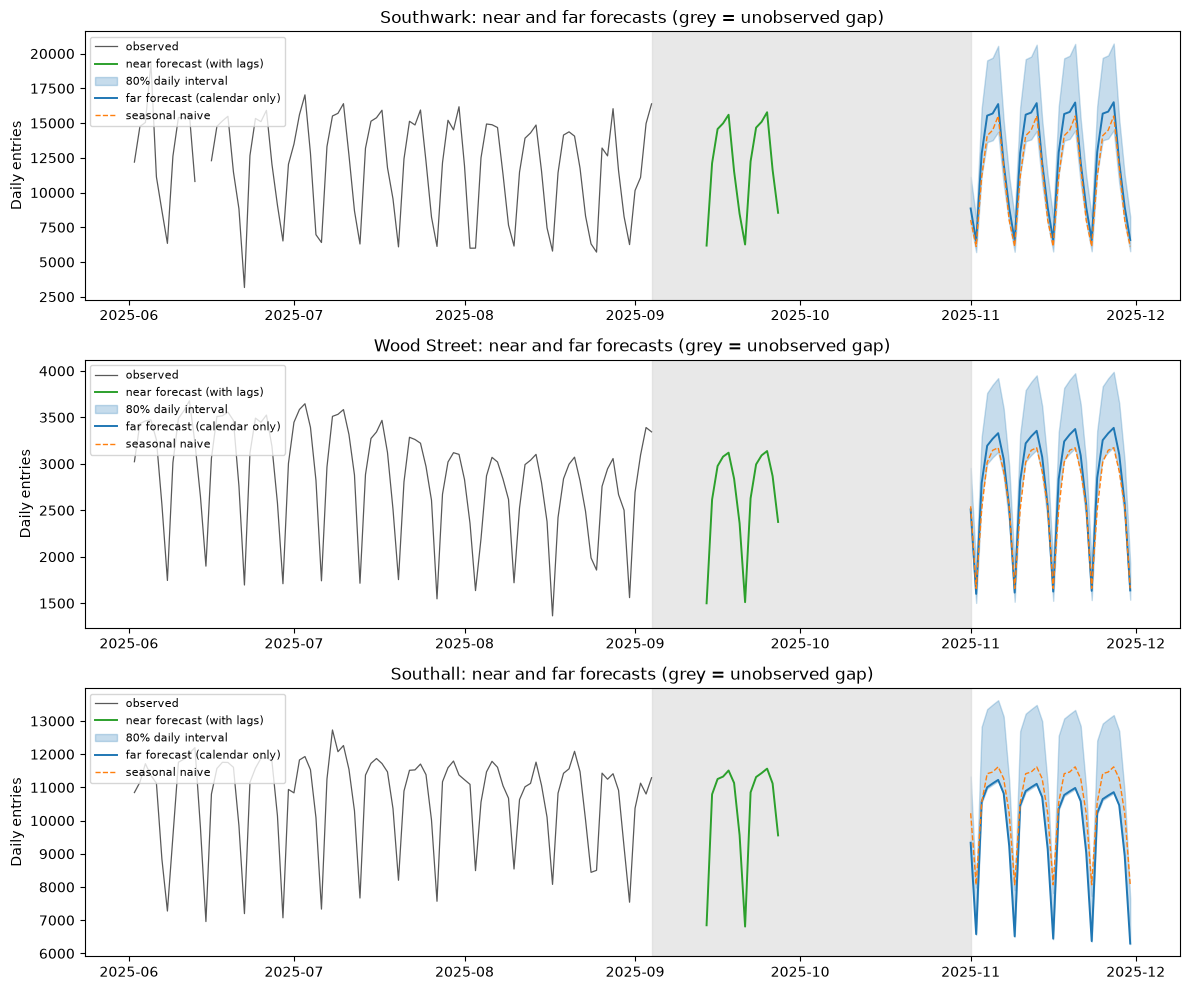

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, s in zip(axes, STATIONS):
    hist = series[s]
    hist = hist[hist["Date"] > "2025-06-01"]
    fc = finals[s]

    near = near_finals[s]

    ax.plot(hist["Date"], hist["y"], color="0.35", lw=0.9, label="observed")
    ax.plot(near["Date"], near["poisson"], color="tab:green", lw=1.4,
            label="near forecast (with lags)")
    ax.fill_between(fc["Date"], fc["day_lo"], fc["day_hi"], alpha=0.25,
                    color="tab:blue", label="80% daily interval")
    ax.plot(fc["Date"], fc["point"], color="tab:blue", lw=1.4,
            label="far forecast (calendar only)")
    ax.plot(fc["Date"], fc["naive"], color="tab:orange", lw=1.0, ls="--",
            label="seasonal naive")
    ax.axvspan(ORIGIN, TARGET.min(), color="0.85", alpha=0.6)
    ax.set_title(f"{s}: near and far forecasts (grey = unobserved gap)")
    ax.set_ylabel("Daily entries")
    ax.legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

In [20]:
panel = pd.concat(
    [fc.assign(Station=s, Horizon="far") for s, fc in finals.items()]
    + [n.assign(Station=s, Horizon="near") for s, n in near_finals.items()],
    ignore_index=True,
)
panel.to_csv(OUT_CSV, index=False)
print(f"Saved {len(panel)} rows to {OUT_CSV}")

Saved 132 rows to ../outputs/november_forecasts.csv


In [21]:
# Backtest error by day type.
rows = []
for s, df in series.items():
    for o in sorted(backtests[s]["origin"].unique()):
        tgt = pd.date_range(pd.Timestamp(o) + pd.Timedelta(days=GAP_DAYS),
                            periods=30, freq="D")
        pred = tfl.forecast(df, pd.Timestamp(o), tgt, models=["poisson"])
        act = df.set_index("Date")["y"].reindex(tgt).values
        rows.append(pd.DataFrame({"station": s,
                                  "weekend": tgt.dayofweek >= 5,
                                  "ae": np.abs(act - pred["poisson"].values)}))

split = pd.concat(rows).dropna()
day_split = split.pivot_table(index="station", columns="weekend", values="ae")
day_split.columns = ["weekday MAE", "weekend MAE"]
day_split["ratio"] = day_split["weekend MAE"] / day_split["weekday MAE"]
print("Poisson GLM absolute error by day type, pooled over backtest origins\n")
print(day_split.round(2).to_string())

# The final observed day (Saturday 13 September 2025) against a typical Saturday.
print()
for s, df in series.items():
    g = df.set_index("Date")
    final = g["Entries"].iloc[-1]
    typical = g[(g.index.dayofweek == g.index[-1].dayofweek) & g["y"].notna()]["y"].median()
    print(f"  {s:22s} final day {final:>8,.0f}   typical {typical:>8,.0f}   ratio {final / typical:.2f}")

# September to November change in 2024, the only year containing both months.
print("\nSeptember -> November shift, 2024\n")
for s, df in series.items():
    d = df.set_index("Date")["y"]
    sep = d.loc["2024-09-01":"2024-09-30"].mean()
    nov = d.loc["2024-11-01":"2024-11-30"].mean()
    print(f"  {s:16s} Sep {sep:8,.0f}   Nov {nov:8,.0f}   {nov / sep - 1:+.1%}")

Poisson GLM absolute error by day type, pooled over backtest origins

             weekday MAE  weekend MAE  ratio
station                                     
Southall         1077.52       974.77   0.90
Southwark        1150.40       965.07   0.84
Wood Street       293.22       252.62   0.86

  Southwark              final day    8,715   typical    8,888   ratio 0.98
  Wood Street            final day    2,594   typical    2,511   ratio 1.03
  Southall               final day    9,166   typical    9,213   ratio 0.99

September -> November shift, 2024

  Southwark        Sep   11,576   Nov   13,140   +13.5%
  Wood Street      Sep    2,747   Nov    2,929   +6.7%
  Southall         Sep   10,118   Nov    9,993   -1.2%
